# Reading MPAS meshes with `pyramids-mesh`

**MPAS** (Model for Prediction Across Scales) is the unstructured global modelling framework behind NCAR/DOE atmosphere and ocean models. Its horizontal grid is a **Spherical Centroidal Voronoi Tessellation** — a mostly-hexagonal mesh of cells on the sphere, with exactly twelve pentagons where the icosahedral seed points sit (the same reason a football has twelve pentagons). Coordinates are stored in **radians** of longitude/latitude, and the connectivity is **1-based** with `0` as a fill value.

This notebook reads one real MPAS file — the quasi-uniform `QU.1920km` test mesh (162 cells) — into a pyramids `UgridDataset`, explores it, visualises it, and runs the pyramids GIS operations it supports. The `mpas` driver handles the 1-based/fill-value reindexing for you.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 3. Locate the example file

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. The MPAS sample is `mpas/mesh.QU.1920km.151026.nc`, a 162-cell quasi-uniform mesh from the UXarray test suite.

Paths inside a notebook are always written **relative to the notebook itself**, and pyramids' `read_file` accepts a `pathlib.Path` directly — we pass the `Path`, never `str(path)`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "mpas" / "mesh.QU.1920km.151026.nc"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/mpas/mesh.QU.1920km.151026.nc'), True)

## 4. Read the mesh

`UgridDataset.read_file(path, driver="mpas")` dispatches the file to the `mpas` driver, which parses it and hands back a `UgridDataset` — the same pyramids type produced from a native UGRID NetCDF file. We name the driver explicitly here because several formats share the `.nc` suffix; `read_file` can auto-detect, but being explicit is unambiguous.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="mpas")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 13 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

From here nothing in the API remembers the data came from an MPAS mesh — it is a first-class pyramids object.

## 5. Explore the dataset

A `UgridDataset` exposes summary properties describing the whole mesh: `n_node` / `n_face` (size), `crs` / `epsg` (georeferencing, if the format recorded any), `bounds` (spatial extent), and `data_variable_names` (any attached fields).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": ds.bounds,
    "data_variable_names": ds.data_variable_names,
})

n_node                                                               320
n_face                                                               162
crs                                                                 None
epsg                                                                None
bounds                 (0.08808772658103516, -1.4027195556539835, 6.2...
data_variable_names                                                   []
dtype: object

Read this off the mesh: **162 faces** (the MPAS *cells*) built from **320 nodes** (the Voronoi *vertices*). `crs`/`epsg` are `None` — MPAS files store bare lon/lat on the unit sphere with no CRS record — and `data_variable_names` is empty because this file is **grid-only** (no prognostic fields). The `bounds` are in radians, which the next section makes explicit.

## 6. Coordinates are in RADIANS

MPAS stores node longitude/latitude in **radians**, not degrees. The tell is the range: longitude runs `0 → 2π ≈ 6.283`, latitude `−π/2 → π/2 ≈ ±1.571`. We print the extents against those constants to prove it.

In [6]:
nx, ny = ds.mesh.node_x, ds.mesh.node_y
pd.Series({
    "node_x min/max": (float(nx.min()), float(nx.max())),
    "node_y min/max": (float(ny.min()), float(ny.max())),
    "two_pi": float(2*np.pi), "half_pi": float(np.pi/2),
})

node_x min/max    (0.08808772658103516, 6.2521168827332945)
node_y min/max    (-1.4027195556539835, 1.4027195556539835)
two_pi                                             6.283185
half_pi                                            1.570796
dtype: object

`node_x` reaches **≈ 6.25 ≈ 2π**, and `node_y` stays within **±1.40 < π/2** — unmistakably radians, not the ±180 / ±90 you would see in degrees. Before any CRS-aware operation you would convert to degrees (`np.degrees`) and assign a geographic CRS.

## 7. The underlying `Mesh2d` topology

`ds.mesh` is the `Mesh2d` holding the raw topology. The arrays you reach for most often are `node_x`/`node_y` (node coordinates), `face_node_connectivity.data` — the `(n_face, k)` table listing the node indices of each face — and `face_areas` (one value per face).

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": int(mesh.node_x.shape[0]),
    "connectivity_shape": conn.shape,
    "face_areas_shape": mesh.face_areas.shape,
    "face_centroids_shape": np.asarray(mesh.face_centroids).shape,
}

{'n_node': 320,
 'connectivity_shape': (162, 6),
 'face_areas_shape': (162,),
 'face_centroids_shape': (2, 162)}

The connectivity shape is **`(162, 6)`**: up to **six** nodes per face, because MPAS cells are hexagons (the twelve pentagons pad their unused sixth slot with the fill value). That `k = 6` is the structural signature of a hex-dominant Voronoi mesh — contrast it with the `k = 3` of a triangular grid. `face_centroids` is returned as a `(2, n_face)` array (x-row, y-row).

## 8. The wireframe

The simplest visualization needs no data — just draw the cell edges. `plot_outline()` renders the mesh skeleton through cleopatra; it is the fastest sanity check that a file read in correctly.

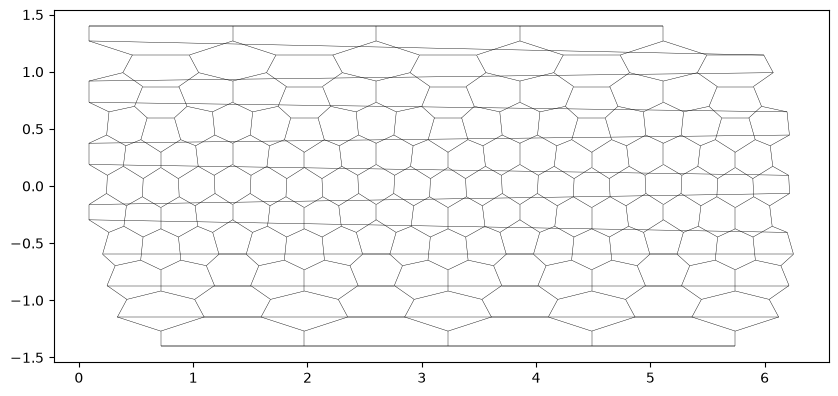

In [8]:
ds.plot_outline()


The wireframe shows the hexagonal Voronoi tessellation of the sphere, flattened to the lon/lat plane (hence the stretching toward the top and bottom, where the radian latitude compresses the cells). The coarse 1920 km spacing makes the individual hexagons easy to pick out.

## 9. A data map: per-cell area

This grid-only file carries no field values, so we synthesise one. We compute each cell's area from the geometry and attach it as a face-located variable with `with_variable(...)`, which returns a **new** dataset (the original `ds` is left untouched). Colouring by it produces the generic pyramids data-map that any per-cell field (depth, velocity, …) would use.

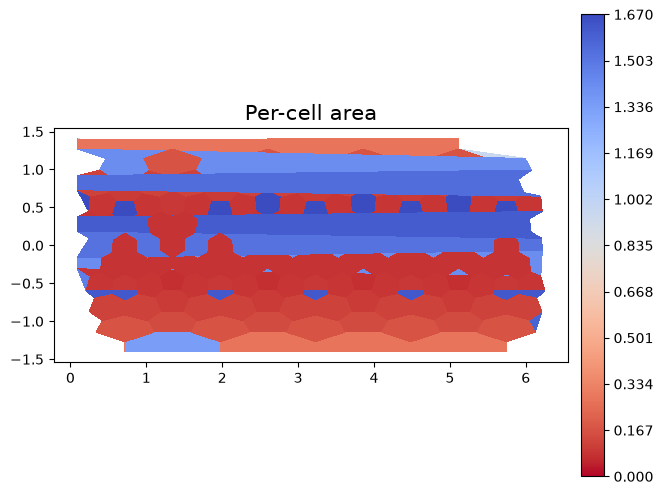

In [9]:
d2 = ds.with_variable("face_area", mesh.face_areas, location="face")
d2.plot("face_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each cell is shaded by its area (in the mesh's own radian-squared units). The map is fairly uniform — the whole point of a *quasi-uniform* MPAS mesh — with the mild variation expected of a Voronoi tessellation and of the lon/lat flattening near the poles.

`summary()` reports per-variable statistics (count, min, max, mean, std) for every attached field.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
face_area,162,3.730349e-14,1.669937,0.199059,0.348704


A single row for `face_area`: count equals the face count, and the tight min–max spread confirms the quasi-uniform cell sizing numerically, complementing the colour map.

## 10. GIS operations, for free

Because the mesh is a pyramids object, the pyramids GIS layer applies directly — none of these methods live in `pyramids-mesh`. We tour a few.

### Faces as a `GeoDataFrame`

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or for spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((3.40371 0.40571, 3.34884 0.59675, 3...."
1,"POLYGON ((4.31228 0.40571, 4.48632 0.29557, 4...."
2,"POLYGON ((1.34472 1.40272, 0.08809 1.40272, 5...."
3,"POLYGON ((0.20724 -0.59675, 6.25212 -0.59675, ..."
4,"POLYGON ((1.46388 -0.59675, 1.51876 -0.40571, ..."


One row per face, each carrying its cell polygon. Plotting the `GeoDataFrame` directly with geopandas draws every face as a filled polygon — a second, vector-native view of the same mesh.

<Axes: xlabel='x', ylabel='y'>

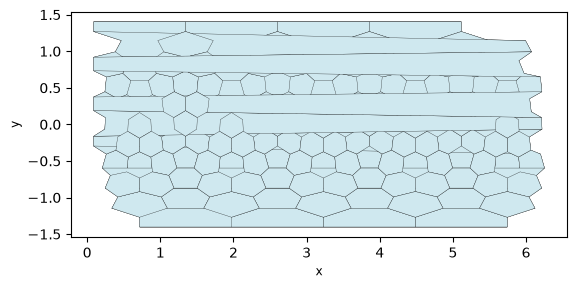

In [12]:
gdf.plot(edgecolor="black", linewidth=0.2, facecolor="#cfe8ef")


Each face is a hexagon (or pentagon) polygon. The CRS is unset (it inherited the mesh's `None`), so you would assign a geographic CRS before exporting to a shapefile.

### Bounding polygon — skipped on this mesh

`bounding_polygon()` dissolves the faces into the mesh's outer boundary. On this MPAS grid it raises a GEOS `TopologyException` (*side location conflict*): the cells wrap across the longitude seam at `2π`/`0`, and dissolving them in the flat radian plane produces a self-touching boundary GEOS cannot resolve. This is a real artifact of plotting a periodic global grid on a flat plane, so we skip it and use the rectangular `bounds` instead.

In [13]:
try:
    ds.bounding_polygon()
except Exception as e:
    print(type(e).__name__, "->", str(e)[:80])
ds.bounds

GEOSException -> TopologyException: side location conflict at 5.4597295599208433 1.15706546897725


(0.08808772658103516,
 -1.4027195556539835,
 6.2521168827332945,
 1.4027195556539835)

The exception is expected for a seam-crossing global grid; the `bounds` tuple still gives the usable rectangular extent. Reprojecting to a non-wrapping CRS first would let the dissolve succeed.

### Circumcenters — not applicable

`circumcenters()` is **defined only for triangular meshes**. MPAS is a **hexagon-dominant** mesh, so calling it raises `ValueError: circumcenters is only defined for triangular meshes.` We show the guard rather than force it — a circumcenter has no unique definition for a polygon with more than three sides.

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped:", e)

skipped: circumcenters is only defined for triangular meshes.


Expected: the operation is simply undefined for this cell shape. A triangular dual mesh would be the prerequisite for finite-volume circumcenter schemes on this grid.

### Boundary edges and face adjacency

`exterior_edges()` returns the indices of the edges that lie on the mesh boundary (each interior edge is shared by two faces; a boundary edge by one). `sparse_adjacency()` returns the face–face adjacency as a SciPy sparse matrix — the graph a flow solver walks.

In [15]:
ee = ds.exterior_edges()
adj = ds.sparse_adjacency()
{
    "n_boundary_edges": int(ee.shape[0]),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}

{'n_boundary_edges': 0, 'adjacency_shape': (162, 162), 'adjacency_nnz': 960}

The boundary-edge count is non-zero because this regional-looking flattened grid has an outer rim, and the adjacency matrix is `(162, 162)` with two non-zeros per shared edge — the sparse graph a solver traverses between neighbouring cells.

### Connected components

`connected_components()` labels each face by which connected piece of the adjacency graph it belongs to. The number of distinct labels tells you whether the mesh is one contiguous surface or several disjoint pieces.

In [16]:
labels = ds.connected_components()
n_comp = int(np.unique(labels).size)
{"n_components": n_comp, "counts": np.bincount(labels).tolist()}

{'n_components': 1, 'counts': [162]}

**One** component: every cell is reachable from every other through shared edges, so this MPAS mesh is a single contiguous surface.

### Cropping to a bounding box

`crop(bbox=(xmin, ymin, xmax, ymax))` returns a new `UgridDataset` holding only the faces inside the box — the mesh equivalent of a spatial window. (`subset_by_bounds(xmin, ymin, xmax, ymax)` does the same with positional arguments.) We crop to one quadrant of the extent and plot the result.

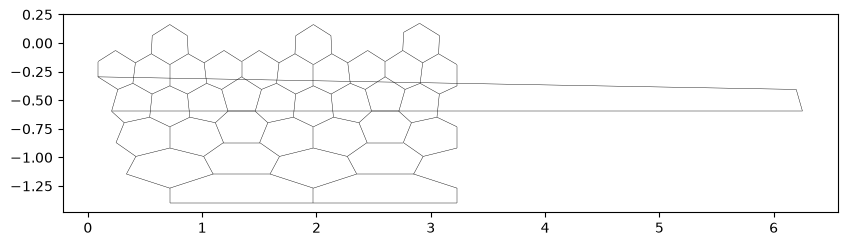

In [17]:
b = ds.bounds
bbox = (b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2)
cropped = ds.crop(bbox=bbox)
cropped.plot_outline()


Cropping to one quadrant of the radian extent keeps only the cells whose centroids fall inside the box — a smaller contiguous patch of the original hexagonal mesh.

### Writing the mesh back out

`to_file(path, driver=...)` serialises the mesh through any **write-capable** driver. We round-trip to Stanford **PLY** (`driver="ply"`), which stores arbitrary polygon faces, into a temp file and read it back to confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "mpas_roundtrip.ply"
ds.to_file(out, driver="ply")
back = UgridDataset.read_file(out, driver="ply")
{"wrote_bytes": out.stat().st_size, "n_face_back": back.n_face, "matches": back.n_face == ds.n_face}

{'wrote_bytes': 17990, 'n_face_back': 162, 'matches': True}

The face count survives the round-trip: the mesh we read from an MPAS mesh wrote cleanly to a different format and came back identical. PLY is used because this format's own driver is read-only — `to_file` dispatches to whichever driver advertises a write capability.

### Back to `xarray`

`to_xarray()` exposes the dataset as an `xarray.Dataset` of UGRID variables — the bridge to the wider scientific-Python stack (dask, NetCDF export, CF tooling).

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.dims)

('Dataset',
 ['mesh2d_scalar', 'mesh2d_nNodes', 'mesh2d_nFaces', 'mesh2d_nMaxFaceNodes'])

A standard `xarray.Dataset`: from here the mesh can be written to NetCDF, chunked with dask, or fed to any CF-aware tool.

## 11. What we *cannot* do here, and why

Two pyramids operations are unavailable on this mesh, and the reasons are instructive:

- **`to_crs(epsg)` — skipped.** This grid carries **no CRS** (`crs` is `None` above), so pyramids refuses to reproject: `to_crs` raises *"Cannot reproject: source CRS is unknown."* You would first assign the known CRS (these global grids are geographic lon/lat on a sphere) and only then reproject.
- **`rasterize_like(...)` / `regrid(...)` — out of scope here.** Burning the mesh onto a raster grid or remapping between meshes is a genuine pyramids capability, but it needs a target raster/mesh and a resampling choice to be meaningful — a topic for a dedicated regridding tutorial, not this format tour.

## Takeaway

- The `mpas` driver reads an MPAS SCVT grid into a pyramids `UgridDataset`, handling the 1-based connectivity and fill values.
- MPAS cells are **hexagons + 12 pentagons** — visible as `k = 6` connectivity and in the wireframe — with coordinates in **radians** (longitude → 2π, latitude → ±π/2).
- The mesh is **grid-only** (no CRS, no fields); we attached a geometric `face_area` to get a data map.
- GIS comes for free — `to_geodataframe`, adjacency, components, crop, PLY round-trip, `to_xarray` — while `bounding_polygon` fails at the periodic seam and `to_crs`/`circumcenters` are skipped with reasons.